# 03 &nbsp;Do our methods actually work on this data?

**The problem.** Every method on a statistics cheat sheet comes with assumptions. A t-test leans on the average being roughly normal. A bootstrap leans on the sample looking like the population. Revenue breaks both easily: fewer than 1 in 100 customers buy anything, and the ones who do spend wildly different amounts. Whether a method still works here is an empirical question, and it has a cheap answer.

**The approach: A/A tests on real data.** Take the 21,306 customers who got **no email** and split them at random into two fake groups, again and again. Nobody got a treatment, so the true effect is exactly zero. A trustworthy method should:

- wrongly flag a "significant" difference about **5%** of the time (its false positive rate), and
- produce 95% intervals that contain zero about **95%** of the time.

Anything else means the method's p-values and intervals can't be taken at face value on this data.

In [1]:
from exptoolkit import plots, style
from exptoolkit.calibration import aa_test, calibration_table
from exptoolkit.data import load_hillstrom
from exptoolkit.estimators import ESTIMATORS

style.use_style()
df = load_hillstrom()
control = df[df["arm"] == "control"]
print(f"{len(control):,} no-email customers, {control['conversion'].mean():.2%} of them bought something")

21,306 no-email customers, 0.57% of them bought something


## 1. Run the A/A tests

Two common methods, two metrics, six test sizes, 1,000 fake experiments each. The Welch t-test is the usual default; the bootstrap is the usual fix people reach for when data looks non-normal. This takes a minute or two.

In [2]:
results = []
for metric in ["spend", "conversion"]:
    for n in [250, 500, 1000, 2500, 5000, 10000]:
        for name, estimator in ESTIMATORS.items():
            extra = {"n_boot": 500} if name == "Bootstrap" else {}
            results.append(
                aa_test(control[metric], estimator, n, n_sims=1000, seed=n,
                        method=name, metric=metric, **extra)
            )
table = calibration_table(results)

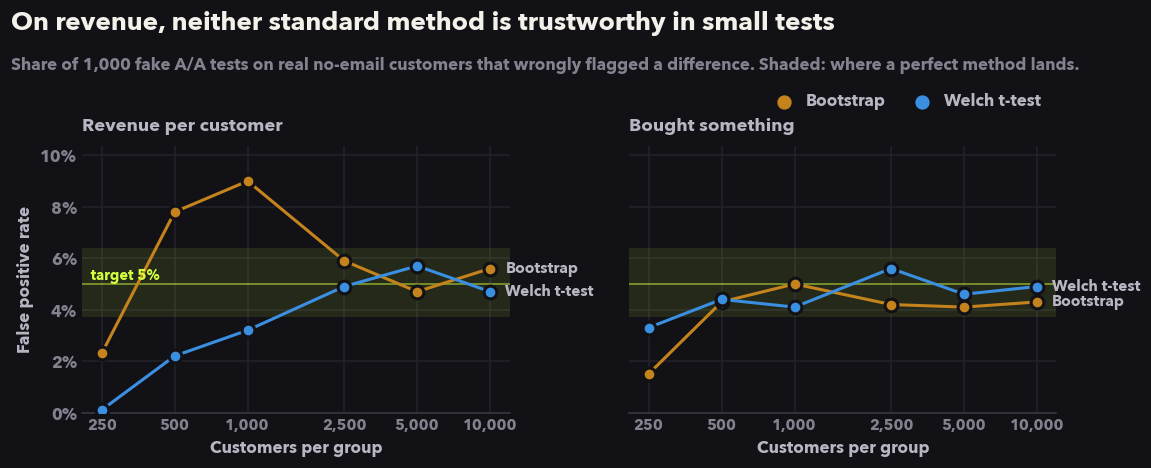

In [3]:
fig, axes = plots.calibration_plot(table, {"spend": "Revenue per customer", "conversion": "Bought something"})
style.headline(
    fig,
    "On revenue, neither standard method is trustworthy in small tests",
    "Share of 1,000 fake A/A tests on real no-email customers that wrongly flagged a difference. "
    "Shaded: where a perfect method lands.",
)
style.save(fig, "calibration")

In [4]:
shown = table.copy()
shown["Metric"] = shown["Metric"].map({"spend": "Revenue", "conversion": "Bought something"})
shown.style.format({
    "Customers per group": "{:,.0f}",
    "False positive rate": "{:.1%}",
    "Interval coverage": "{:.1%}",
}).hide(axis="index")

Method,Metric,Customers per group,False positive rate,Interval coverage,Expected range,Calibrated
Welch t-test,Revenue,250,0.1%,99.9%,3.7% to 6.4%,False
Bootstrap,Revenue,250,2.3%,97.1%,3.7% to 6.4%,False
Welch t-test,Revenue,500,2.2%,97.8%,3.7% to 6.4%,False
Bootstrap,Revenue,500,7.8%,91.6%,3.7% to 6.4%,False
Welch t-test,Revenue,"1,000",3.2%,96.8%,3.7% to 6.4%,False
Bootstrap,Revenue,"1,000",9.0%,90.9%,3.7% to 6.4%,False
Welch t-test,Revenue,"2,500",4.9%,95.1%,3.7% to 6.4%,True
Bootstrap,Revenue,"2,500",5.9%,94.0%,3.7% to 6.4%,True
Welch t-test,Revenue,"5,000",5.7%,94.3%,3.7% to 6.4%,True
Bootstrap,Revenue,"5,000",4.7%,94.9%,3.7% to 6.4%,True


## 2. What the A/A tests show

**On revenue, both methods fail in small tests, in opposite directions.**

- The **t-test is too cautious.** With 250 customers per group it raised a false alarm in 0.1% of tests instead of 5%. That sounds safe, but a method that never fires on nothing will also miss real effects.
- The **bootstrap is too eager.** With 1,000 per group it raised a false alarm in 9% of tests, nearly double the promised 5%. This is the method people switch to *because* the data looks skewed.
- **Both settle from about 2,500 customers per group.**

**On purchases (a yes/no outcome), both methods are fine from 500 per group.**

**Why.** At 0.57% buying, 1,000 customers means about 6 buyers per group. Revenue is then decided by a handful of orders. The t-test's error estimate swings wildly with them, and the bootstrap can only reshuffle the few big orders it happened to see, so it underestimates how much the next sample could differ. What matters is **how many buyers** each group has, not how many customers: in this data, both methods behave once each group has around **15 buyers**.

In [5]:
rate = control["conversion"].mean()
for n in [250, 1000, 2500, 21306]:
    print(f"{n:>6,} customers per group  ->  about {n * rate:5.1f} buyers")

   250 customers per group  ->  about   1.4 buyers
 1,000 customers per group  ->  about   5.7 buyers
 2,500 customers per group  ->  about  14.3 buyers
21,306 customers per group  ->  about 122.0 buyers


## 3. What this means for the decision

- **The main readout is safe.** Each group in this test has over 21,000 customers and about 120 to 270 buyers, far inside the zone where both methods are calibrated. Notebook 06 can use them with confidence.
- **Segment analysis is not automatically safe.** Slicing by channel, area or customer history quickly produces groups with a few dozen buyers. Those cuts need this same check before anyone quotes a p-value from them, and it matters most for the targeting work in notebook 08.
- **Size tests by buyers, not by customers.** That is the starting point for notebook 04, which sizes tests by simulation on this same data instead of a textbook formula.

**The general habit:** before trusting a method on a new metric or a new slice, run it on an A/A split of that exact data. It takes a minute and replaces an assumption with evidence.